# 04 · IPCA — instrumented principal components (Kelly, Pruitt & Su, 2019)

**Purpose.** Let factor loadings vary across assets and over time as linear
functions of observable characteristics: $\beta_{i,t}=z_{i,t}'\Gamma_\beta$.
Works on large, **unbalanced** panels of individual assets and tests whether
characteristics carry alpha beyond risk ($\Gamma_\alpha=0$).

**Model.**
$r_{i,t}=z_{i,t}'\Gamma_\alpha+z_{i,t}'\Gamma_\beta f_t+z_{i,t}'\Gamma_\delta g_t+\varepsilon_{i,t}$,
estimated by alternating least squares on managed portfolios
$X_t=Z_t'r_t/N_t$, $W_t=Z_t'Z_t/N_t$.

| Parameter | Default | Options |
|---|---|---|
| `n_factors` | 1 | latent factors $K$ |
| `intercept` | `False` | estimate $\Gamma_\alpha$ (unrestricted model) |
| `max_iter`, `tol` | 10000, 1e-6 | ALS stopping rule |
| `weighting` | `"observations"` | equal weight per stock-period, or `"periods"` |

**Timing.** The instruments in row $t$ of the panel must be known before the
return in row $t$ — lag your characteristics before building the panel.

### How to run this notebook

```bash
pip install -e ".[notebooks]"        # package + jupyter, matplotlib, pandas
jupyter lab examples/                 # or: jupyter notebook examples/
```

All data are **synthetic with known ground truth** (generated by
`lfm.simulate_factor_returns` / `lfm.simulate_ipca_panel`), so every cell runs
offline in seconds and estimates can be compared with the truth. To use your
own data, replace the simulation cell by a `pandas.DataFrame` of excess returns
(dates x assets); every estimator accepts DataFrames directly.

In [1]:
# Setup: imports, plotting defaults and reproducibility
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import latent_factor_models as lfm

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3})
print("latent-factor-models", lfm.__version__)

latent-factor-models 0.1.0


## 1. A characteristic panel

`CharacteristicPanel` stores returns $T\times N$ (NaN = missing) and
instruments $T\times N\times L$. Build it from arrays, from a long `DataFrame`
(`CharacteristicPanel.from_long`) or from the stacked layout `[id, t, y, z...]`.
Here instrument 0 is **irrelevant** for betas, so the instrument test should not
reject for it.

In [2]:
sim = lfm.simulate_ipca_panel(T=200, N=300, L=6, K=2, missing=0.1, irrelevant=1, seed=0)
panel = sim.panel
print(f"T={panel.T}, N={panel.N}, L={panel.L}, observed share={panel.mask.mean():.2f}")

T=200, N=300, L=6, observed share=0.90


In [3]:
# The same panel from a long-format DataFrame (typical for CRSP/Compustat data)
t, i = np.nonzero(panel.mask)
long = pd.DataFrame(
    {
        "date": t,
        "permno": i,
        "ret": panel.returns[t, i],
        **{f"z{j}": panel.characteristics[t, i, j] for j in range(panel.L)},
    }
)
panel2 = lfm.CharacteristicPanel.from_long(
    long,
    entity="permno",
    time="date",
    target="ret",
    characteristics=[f"z{j}" for j in range(panel.L)],
)
print(
    "identical to the array-based panel:",
    np.allclose(panel2.returns, panel.returns, equal_nan=True),
)
long.head(3)

identical to the array-based panel: True


,date,permno,ret,z0,z1,z2,z3,z4,z5
0,0,1,-0.6367,0.1744,0.4070,0.3140,-0.2309,-0.4236,1.0
1,0,2,0.3246,-0.2076,0.0515,-0.4834,-0.0581,-0.4136,1.0
2,0,3,-0.9174,-0.2542,-0.1811,-0.1578,0.1811,0.3206,1.0


## 2. Estimation and outputs

In [4]:
model = lfm.IPCA(n_factors=2).fit(panel)
print(f"converged={model.converged_} in {model.n_iter_} iterations")
pd.Series(model.evaluate(), name="fit (uncentred R²)")

converged=True in 7 iterations


total_r2      0.2590
total_r2_x    0.9917
pred_r2       0.0143
pred_r2_x     0.0254
Name: fit (uncentred R²), dtype: float64

| Output | Shape | Meaning |
|---|---|---|
| `gamma_beta_` | $L\times K$ | characteristics → betas |
| `gamma_alpha_` | $L$ | characteristics → alpha (zeros if `intercept=False`) |
| `gamma_delta_` | $L\times M$ | loadings on observed factors |
| `factors_` | $T\times K$ | latent factor returns |
| `loadings(panel)` | $T\times N\times K$ | time-varying betas $z_{i,t}'\Gamma_\beta$ |
| `predict(panel, factors="realized"/"mean")` | $T\times N$ | fitted / predicted returns |
| `transform(panel)` | $T'\times K$ | out-of-sample factors (cross-sectional regressions) |
| `evaluate(panel)` | dict | total and predictive $R^2$, assets and managed portfolios |

distance to the true Γβ subspace: 0.7177


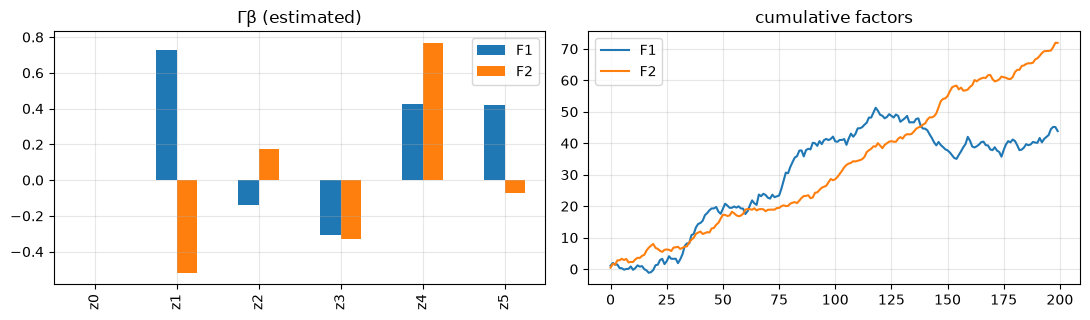

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
pd.DataFrame(
    model.gamma_beta_, index=[f"z{j}" for j in range(panel.L)], columns=["F1", "F2"]
).plot.bar(ax=ax[0], title="Γβ (estimated)")
pd.DataFrame(model.factors_, columns=["F1", "F2"]).cumsum().plot(
    ax=ax[1], title="cumulative factors"
)
plt.tight_layout()
err = np.linalg.norm(model.gamma_beta_ @ model.gamma_beta_.T - sim.gamma_beta @ sim.gamma_beta.T)
print(f"distance to the true Γβ subspace: {err:.4f}")

## 3. Bootstrap tests (parallel)

Wild residual bootstrap of Kelly-Pruitt-Su (Student-t(5) multipliers scaled to
unit variance). Each draw re-estimates the model and is an independent task
for the `Executor`; results are reproducible given `seed`.

BootstrapResult(Gamma_alpha = 0: W=0.00047893, p=0.6850, draws=200)


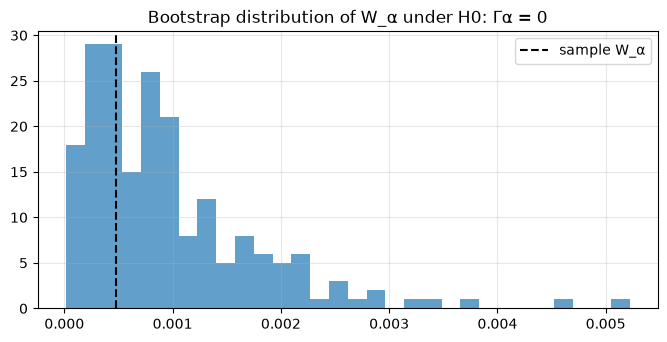

In [6]:
unrestricted = lfm.IPCA(2, intercept=True).fit(panel)
test = unrestricted.test_alpha(n_draws=200, seed=1, executor="thread", n_jobs=4)
print(test)
plt.hist(test.draws, bins=30, alpha=0.7)
plt.axvline(test.statistic, color="k", ls="--", label="sample W_α")
plt.legend()
plt.title("Bootstrap distribution of W_α under H0: Γα = 0");

In [7]:
rows = {
    f"z{j}": model.test_instrument(j, n_draws=100, seed=j, executor="thread", n_jobs=4)
    for j in range(panel.L)
}
pd.DataFrame(
    {"W": [r.statistic for r in rows.values()], "p-value": [r.pvalue for r in rows.values()]},
    index=list(rows),
)

,W,p-value
z0,5.2310e-06,0.99
z1,7.9606e-01,0.00
z2,4.8704e-02,0.00
z3,2.0341e-01,0.00
z4,7.7206e-01,0.00
z5,1.7976e-01,0.00


Instrument `z0` was simulated as irrelevant: its p-value is large; all others
are rejected. Use `test_instrument([l1, l2])` for joint tests and
`test_observed_factors()` for $\Gamma_\delta=0$. `block_size` gives a block-wild
bootstrap for serially dependent residuals.

## 4. Observed factors and out-of-sample evaluation

In [8]:
g = sim.factors[:, :1] + 0.3 * np.random.default_rng(0).standard_normal((panel.T, 1))
with_obs = lfm.IPCA(1).fit(panel, factors=g)
print(
    "Γδ shape:",
    with_obs.gamma_delta_.shape,
    "| fit:",
    {k: round(v, 4) for k, v in with_obs.evaluate().items()},
)

Γδ shape: (6, 1) | fit: {'total_r2': 0.2508, 'total_r2_x': 0.9834, 'pred_r2': 0.1272, 'pred_r2_x': 0.5162}


In [9]:
# Recursive (expanding-window) out-of-sample R², refit every 20 periods
lfm.Engine([lfm.IPCA(1), lfm.IPCA(2), lfm.IPCA(3)]).out_of_sample(
    panel, window=120, refit_every=20, expanding=True
).to_frame()

,model,sample,total_r2,pred_r2,n_windows
0,IPCA(n_factors=1),out-of-sample,0.2067,-0.0320,4
1,IPCA(n_factors=2),out-of-sample,0.2437,-0.0217,4
2,IPCA(n_factors=3),out-of-sample,0.2459,-0.0220,4


**Validation.** Identical to the original `ipca` package (bkelly-lab) for Γ,
factors and fitted values. The package reports the paper's *uncentred* $R^2$;
the original's `score()` reports a centred one.